In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from irregts import (
    structure_function,
    characteristic_timescale,
    dcf,
    calculate_dcf_centroid,
    bootstrap_dcf_significance,
    bootstrap_timescale_uncertainty,
    plot_combined_analysis,
    print_enhanced_timescale_report,
    print_dcf_binning_info,
    print_dcf_significance,
    print_dcf_peak_vs_centroid,
    save_sf_to_csv,
    save_dcf_to_csv
)

In [2]:
#Processing ZTF zr data for plotting
ztf_zr_filename = '/home/arpan/project_root/sample_data/mrk290/table_ZTF-LC-zr-Data.tbl'

#Step 1: read the headers information to gather the column headers
with open(ztf_zr_filename, "r") as f:
    ztf_zr_header_lines = f.readlines()

# find the line that contains column names
ztf_zr_header_line = None
for line in ztf_zr_header_lines:
    if line.strip().startswith("|"):
        ztf_zr_header_line = line.strip()
        break

# extract column names
ztf_zr_cols = [col.strip() for col in ztf_zr_header_line.split("|") if col.strip()]


filename = ztf_zr_filename

clean_lines = []

with open(filename, "r") as f:
    for line in f:
        line_strip = line.strip()

        # skip metadata + header + type lines
        if (
            not line_strip or
            line_strip.startswith("\\") or
            line_strip.startswith("|")
        ):
            continue

        parts = line_strip.split()

        # keep only valid rows with correct column count
        if len(parts) == len(ztf_zr_cols):
            clean_lines.append(parts)

# create dataframe
ztf_zr_df = pd.DataFrame(clean_lines, columns=ztf_zr_cols)

for col in ztf_zr_df.columns:
    ztf_zr_df[col] = pd.to_numeric(ztf_zr_df[col], errors='coerce')

ztf_zr_df_det = ztf_zr_df[ztf_zr_df['mag'] < ztf_zr_df['limitmag']]
ztf_zr_df_ul = ztf_zr_df[ztf_zr_df['mag'] >= ztf_zr_df['limitmag']]

In [3]:
#Processing ZTF zg data for plotting
ztf_zg_filename = '/home/arpan/project_root/sample_data/mrk290/table_ZTF-LC-zg-Data.tbl'

#Step 1: read the headers information to gather the column headers
with open(ztf_zg_filename, "r") as f:
    ztf_zg_header_lines = f.readlines()

# find the line that contains column names
ztf_zg_header_line = None
for line in ztf_zg_header_lines:
    if line.strip().startswith("|"):
        ztf_zg_header_line = line.strip()
        break

# extract column names
ztf_zg_cols = [col.strip() for col in ztf_zg_header_line.split("|") if col.strip()]


filename = ztf_zg_filename

clean_lines = []

with open(filename, "r") as f:
    for line in f:
        line_strip = line.strip()

        # skip metadata + header + type lines
        if (
            not line_strip or
            line_strip.startswith("\\") or
            line_strip.startswith("|")
        ):
            continue

        parts = line_strip.split()

        # keep only valid rows with correct column count
        if len(parts) == len(ztf_zg_cols):
            clean_lines.append(parts)

# create dataframe
ztf_zg_df = pd.DataFrame(clean_lines, columns=ztf_zg_cols)

for col in ztf_zg_df.columns:
    ztf_zg_df[col] = pd.to_numeric(ztf_zg_df[col], errors='coerce')

ztf_zg_df_det = ztf_zg_df[ztf_zg_df['mag'] < ztf_zg_df['limitmag']]
ztf_zg_df_ul = ztf_zg_df[ztf_zg_df['mag'] >= ztf_zg_df['limitmag']]

In [4]:
# =====================================================================
# SEASON 1 (MJD 58200 to 58400)
# =====================================================================
mask_zg_s1 = (ztf_zg_df_det['mjd'] >= 58200) & (ztf_zg_df_det['mjd'] <= 58400)
mask_zr_s1 = (ztf_zr_df_det['mjd'] >= 58200) & (ztf_zr_df_det['mjd'] <= 58400)

zg_s1 = ztf_zg_df_det[mask_zg_s1]
zr_s1 = ztf_zr_df_det[mask_zr_s1]


In [5]:
#Compute the structure function of continuum ZTF g and r band light curves for season 1
tau_mrk290_zg, sf_mrk290_zg, sf_mrk290_zg_err, n_mrk290_zg = structure_function(zg_s1['mjd'], zg_s1['mag'],
                                                                zg_s1['magerr'])

tau_mrk290_zr, sf_mrk290_zr, sf_mrk290_zr_err, n_mrk290_zr = structure_function(zr_s1['mjd'], zr_s1['mag'], 
                                                                zr_s1['magerr'] )

In [6]:
# --- Compute Discrete Correlation Function for Season 1---
lag_mid, dcf_vals, dcf_err, meta = dcf(
    zr_s1['mjd'], zr_s1['mag'], 
    zg_s1['mjd'], zg_s1['mag'], 
    err1=zr_s1['magerr'], err2=zg_s1['magerr'],
    n_bins=None,lag_range=[-100,100]
)



/home/arpan/project_root/irregts/utils.py:128: RuntimeWarning: Bin width (1.00) is 20.9× larger than the adopted Nyquist limit (0.05). Temporal features narrower than roughly 1.0 time units may be blurred. Consider narrowing lag_range or increasing n_bins.
  warnings.warn(


             IRREGULAR TIME SERIES ANALYSIS REPORT          

Structure Function Timescale Analysis [Mrk 290 zr]
------------------------------------------------------------
  Characteristic Timescale : 39.405 time units
  Bootstrap 1-σ Error Bar  : -8.067 / +17.691 (Median: 47.492)
------------------------------------------------------------

Structure Function Timescale Analysis [Mrk 290 zg]
------------------------------------------------------------
  Characteristic Timescale : 28.349 time units
  Bootstrap 1-σ Error Bar  : -26.350 / +25.977 (Median: 53.732)
------------------------------------------------------------

DCF Lag Bin Configuration (Auto-Driven)
--------------------------------------------------
  Lag Search Range  : -100.00 → 100.00
  Bin Count         : 200
  Bin Width         : 1.00
  Nyquist Limit     : 0.05
  Cadence (t1 / t2) : 0.02 / 0.02
  Total Cross-Pairs : 146,800
--------------------------------------------------
--------------------------------------------

/home/arpan/project_root/irregts/visualization.py:200: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


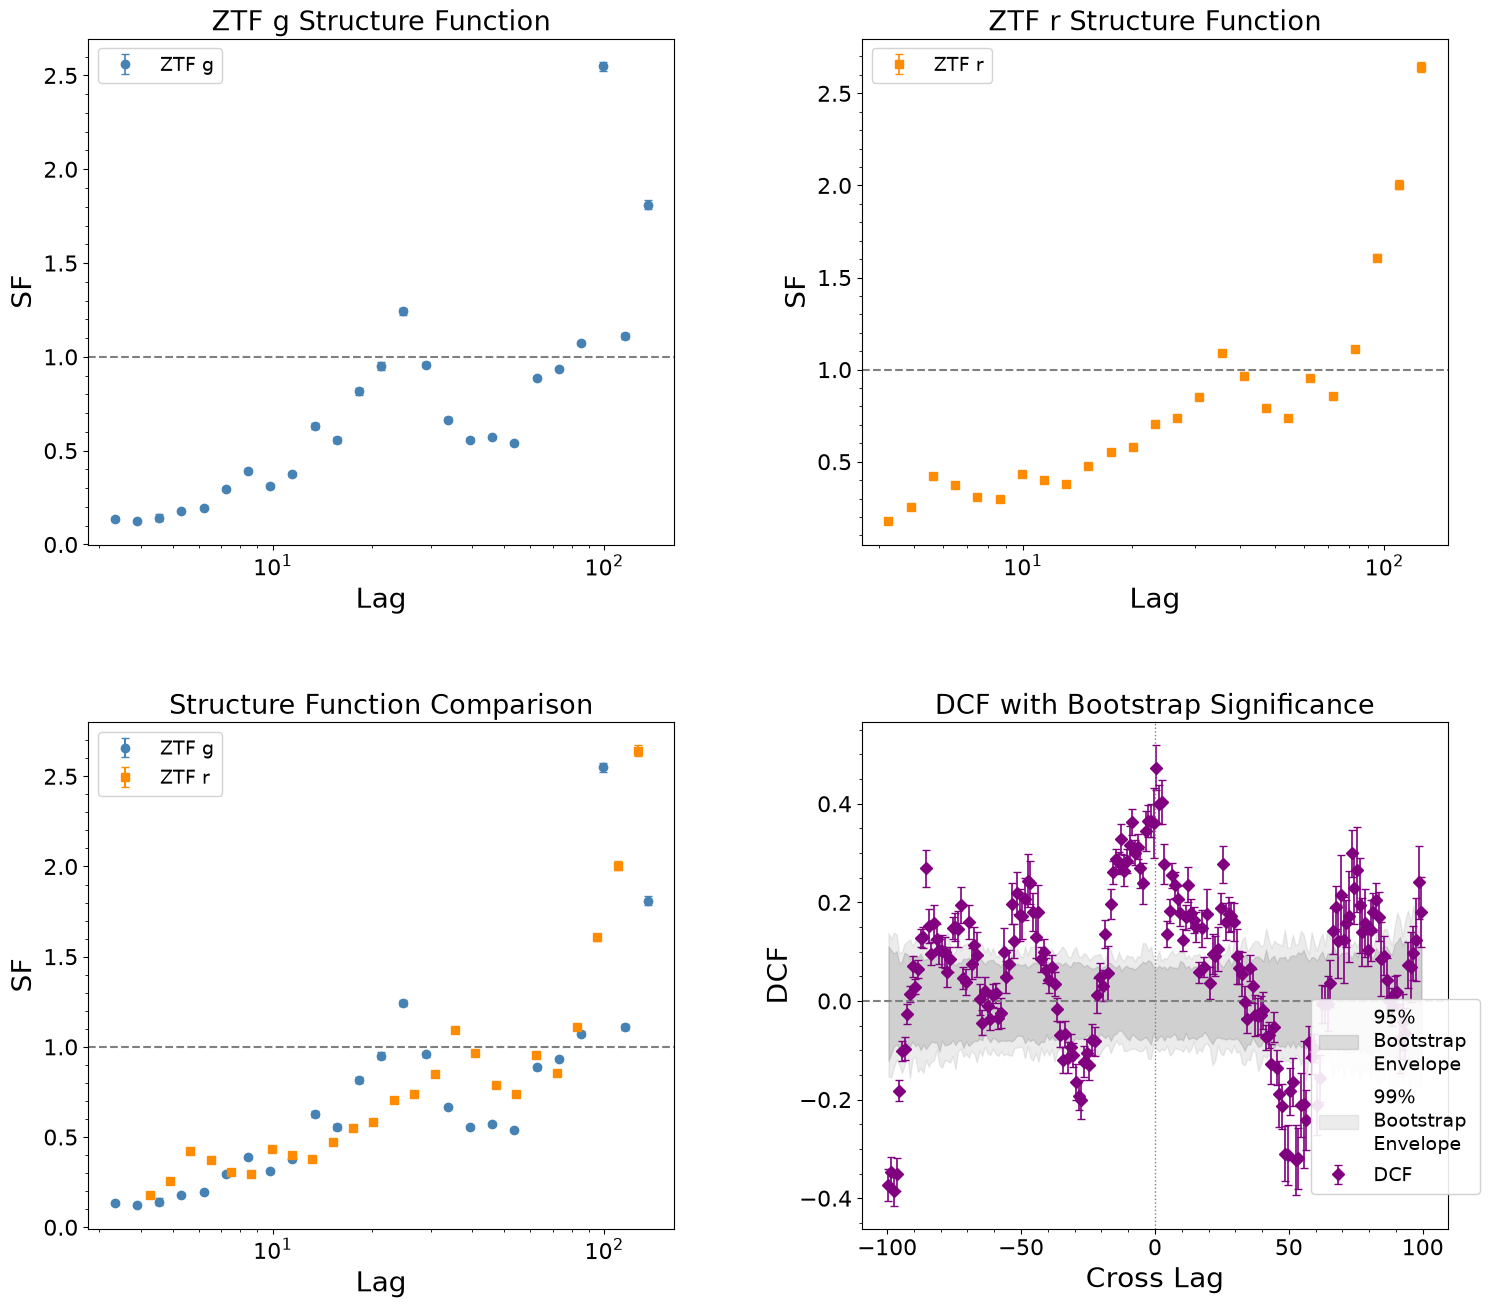

In [7]:
#--- 5. Bootstrap Loops for season 1---
# A. DCF Significance Envelopes
p95, p99 = bootstrap_dcf_significance(
    zr_s1['mjd'], zr_s1['mag'],
    zg_s1['mjd'], zg_s1['mag'],
    zr_s1['magerr'], zg_s1['magerr'] ,
    meta = meta, n_bins=None,
    lag_range=[-100, 100], n_bootstrap=500)

# B. Structure Function Characteristic Timescale Uncertainty (68% Confidence)
ts_med_mrk290_zr, ts_low_mrk290_zr, ts_up_mrk290_zr = bootstrap_timescale_uncertainty(
     zr_s1['mjd'], zr_s1['mag'], err=zr_s1['magerr'], n_bins=None, n_boot=100 )
ts_med_mrk290_zg, ts_low_mrk290_zg, ts_up_mrk290_zg = bootstrap_timescale_uncertainty(
     zg_s1['mjd'], zg_s1['mag'], err=zg_s1['magerr'], n_bins=None, n_boot=100 )

# --- 6. Execute Enhanced Executive Reporting Dashboards ---
print("=" * 60)
print("             IRREGULAR TIME SERIES ANALYSIS REPORT          ")
print("=" * 60)

# A. Display detailed characteristic timescale constraints
print_enhanced_timescale_report("Mrk 290 zr", zr_s1['mjd'], zr_s1['mag'],zr_s1['magerr'])
print_enhanced_timescale_report("Mrk 290 zg", zg_s1['mjd'], zg_s1['mag'],zg_s1['magerr'] )

# B. Evaluate whether the target lag is physically resolvable under Nyquist
print_dcf_binning_info(meta)

# C. Localization comparison: Absolute Peak vs. Flux-Weighted Centroid
print_dcf_peak_vs_centroid(lag_mid, dcf_vals)

# D. Threshold testing
print_dcf_significance(lag_mid, dcf_vals, p95, p99)


# --- 7. Reproducible CSV Data Serialization ---
print("\n[Data Serialization]")
save_sf_to_csv("MRK290_zg_structure_function_s1.csv", tau_mrk290_zg, sf_mrk290_zg, sf_mrk290_zg_err, n_mrk290_zg)
save_sf_to_csv("MRK290_zr_structure_function_s1.csv", tau_mrk290_zr, sf_mrk290_zr, sf_mrk290_zr_err, n_mrk290_zr)
save_dcf_to_csv("MRK290_zg_vs_zr_correlation_s1.csv", lag_mid, dcf_vals, dcf_err, p95=p95, p99=p99)


# --- 8. Render Visualizations with Bound Overlays ---
fig = plot_combined_analysis(
    tau_mrk290_zg, sf_mrk290_zg, sf_mrk290_zg_err,
    tau_mrk290_zr, sf_mrk290_zr, sf_mrk290_zr_err,
    lag_mid, dcf_vals, dcf_err,
    label_a='ZTF g',
    label_b='ZTF r',
    p95=p95,
    p99=p99
)

# Matplotlib automatically fits the vertical text elements without clipping margins
plt.show()

In [8]:

# =====================================================================
# SEASON 2 (MJD 58450 to 58800) 
# =====================================================================
mask_zg_s2 = (ztf_zg_df_det['mjd'] >= 58450) & (ztf_zg_df_det['mjd'] <= 58800)
mask_zr_s2 = (ztf_zr_df_det['mjd'] >= 58450) & (ztf_zr_df_det['mjd'] <= 58800)

zg_s2 = ztf_zg_df_det[mask_zg_s2]
zr_s2 = ztf_zr_df_det[mask_zr_s2]





In [9]:
#Compute the structure function of continuum ZTF g and r band light curves for season 2
tau_mrk290_zg_s2, sf_mrk290_zg_s2, sf_mrk290_zg_err_s2, n_mrk290_zg_s2 = structure_function(zg_s2['mjd'], zg_s2['mag'],
                                                                zg_s2['magerr'])

tau_mrk290_zr_s2, sf_mrk290_zr_s2, sf_mrk290_zr_err_s2, n_mrk290_zr_s2 = structure_function(zr_s2['mjd'], zr_s2['mag'], 
                                                                zr_s2['magerr'] )

In [10]:
# --- Compute Discrete Correlation Function for Season 2---
lag_mid_s2, dcf_vals_s2, dcf_err_s2, meta_s2 = dcf(
    zr_s2['mjd'], zr_s2['mag'], 
    zg_s2['mjd'], zg_s2['mag'], 
    err1=zr_s2['magerr'], err2=zg_s2['magerr'],
    n_bins=None,lag_range=[-100,100]
)


/home/arpan/project_root/irregts/utils.py:128: RuntimeWarning: Bin width (1.00) is 3.6× larger than the adopted Nyquist limit (0.28). Temporal features narrower than roughly 1.0 time units may be blurred. Consider narrowing lag_range or increasing n_bins.
  warnings.warn(


             IRREGULAR TIME SERIES ANALYSIS REPORT          

Structure Function Timescale Analysis [Mrk 290 zr]
------------------------------------------------------------
  Characteristic Timescale : 50.799 time units
  Bootstrap 1-σ Error Bar  : -1.494 / +1.294 (Median: 50.535)
------------------------------------------------------------

Structure Function Timescale Analysis [Mrk 290 zg]
------------------------------------------------------------
  Characteristic Timescale : 50.246 time units
  Bootstrap 1-σ Error Bar  : -1.568 / +1.357 (Median: 50.702)
------------------------------------------------------------

DCF Lag Bin Configuration (Auto-Driven)
--------------------------------------------------
  Lag Search Range  : -100.00 → 100.00
  Bin Count         : 200
  Bin Width         : 1.00
  Nyquist Limit     : 0.28
  Cadence (t1 / t2) : 0.06 / 0.14
  Total Cross-Pairs : 68,850
--------------------------------------------------
------------------------------------------------

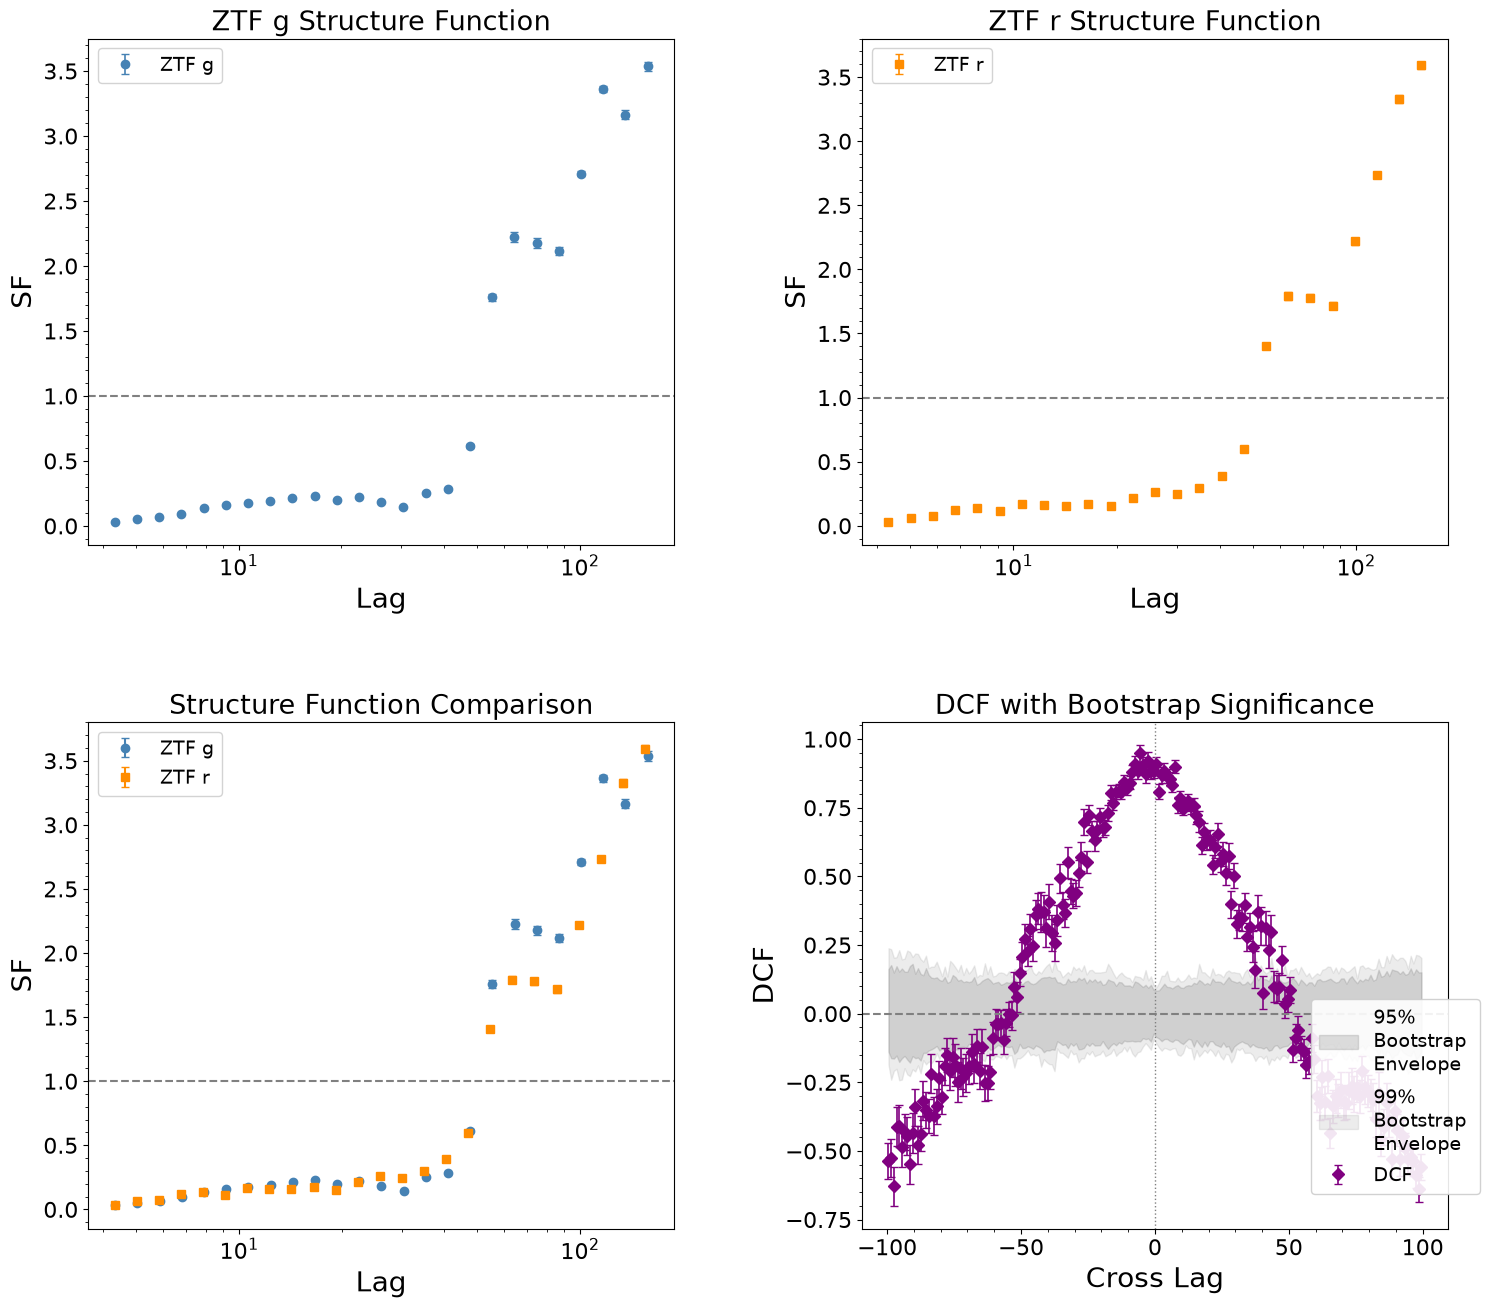

In [11]:
#--- 5. Bootstrap Loops for season 2---
# A. DCF Significance Envelopes
p95_s2, p99_s2 = bootstrap_dcf_significance(
    zr_s2['mjd'], zr_s2['mag'],
    zg_s2['mjd'], zg_s2['mag'],
    zr_s2['magerr'], zg_s2['magerr'], meta = meta_s2, n_bins=None, 
    lag_range=[-100, 100], n_bootstrap=500)

# B. Structure Function Characteristic Timescale Uncertainty (68% Confidence)
ts_med_mrk290_zr, ts_low_mrk290_zr, ts_up_mrk290_zr = bootstrap_timescale_uncertainty(
     zr_s2['mjd'], zr_s2['mag'], err=zr_s2['magerr'], n_bins=None, n_boot=100 )
ts_med_mrk290_zg, ts_low_mrk290_zg, ts_up_mrk290_zg = bootstrap_timescale_uncertainty(
     zg_s2['mjd'], zg_s2['mag'], err=zg_s2['magerr'], n_bins=None, n_boot=100 )

# --- 6. Execute Enhanced Executive Reporting Dashboards ---
print("=" * 60)
print("             IRREGULAR TIME SERIES ANALYSIS REPORT          ")
print("=" * 60)

# A. Display detailed characteristic timescale constraints
print_enhanced_timescale_report("Mrk 290 zr", zr_s2['mjd'], zr_s2['mag'],zr_s2['magerr'])
print_enhanced_timescale_report("Mrk 290 zg", zg_s2['mjd'], zg_s2['mag'],zg_s2['magerr'] )

# B. Evaluate whether the target lag is physically resolvable under Nyquist
print_dcf_binning_info(meta_s2)

# C. Localization comparison: Absolute Peak vs. Flux-Weighted Centroid
print_dcf_peak_vs_centroid(lag_mid_s2, dcf_vals_s2)

# D. Threshold testing
print_dcf_significance(lag_mid_s2, dcf_vals_s2, p95_s2, p99_s2)


# --- 7. Reproducible CSV Data Serialization ---
print("\n[Data Serialization]")
save_sf_to_csv("MRK290_zg_structure_function_s2.csv", tau_mrk290_zg_s2, sf_mrk290_zg_s2, sf_mrk290_zg_err_s2, n_mrk290_zg_s2)
save_sf_to_csv("MRK290_zr_structure_function_s2.csv", tau_mrk290_zr_s2, sf_mrk290_zr_s2, sf_mrk290_zr_err_s2, n_mrk290_zr_s2)
save_dcf_to_csv("MRK290_zg_vs_zr_correlation_s2.csv", lag_mid_s2, dcf_vals_s2, dcf_err_s2, p95=p95_s2, p99=p99_s2)


# --- 8. Render Visualizations with Bound Overlays ---
fig = plot_combined_analysis(
    tau_mrk290_zg_s2, sf_mrk290_zg_s2, sf_mrk290_zg_err_s2,
    tau_mrk290_zr_s2, sf_mrk290_zr_s2, sf_mrk290_zr_err_s2,
    lag_mid_s2, dcf_vals_s2, dcf_err_s2,
    label_a='ZTF g',
    label_b='ZTF r',
    p95=p95_s2,
    p99=p99_s2
)

# Matplotlib automatically fits the vertical text elements without clipping margins
plt.show()